# House Prices - Evaluation & Submission

Final step: diagnose the selected model from
[`02-Modeling.ipynb`](02-Modeling.ipynb), inspect what drives its predictions, and
produce the Kaggle submission file.

## 1. Imports & load artefacts

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 6)

PROC = Path("../data/processed")
model = joblib.load(PROC / "best_model.pkl")
val = pd.read_csv(PROC / "val_predictions.csv")
importance = pd.read_csv(PROC / "feature_importance.csv", index_col=0)["importance"]
print("Loaded model:", type(model).__name__)

Loaded model: Pipeline


## 2. Predicted vs. actual (validation set)

On the log scale, a good model produces points hugging the diagonal.

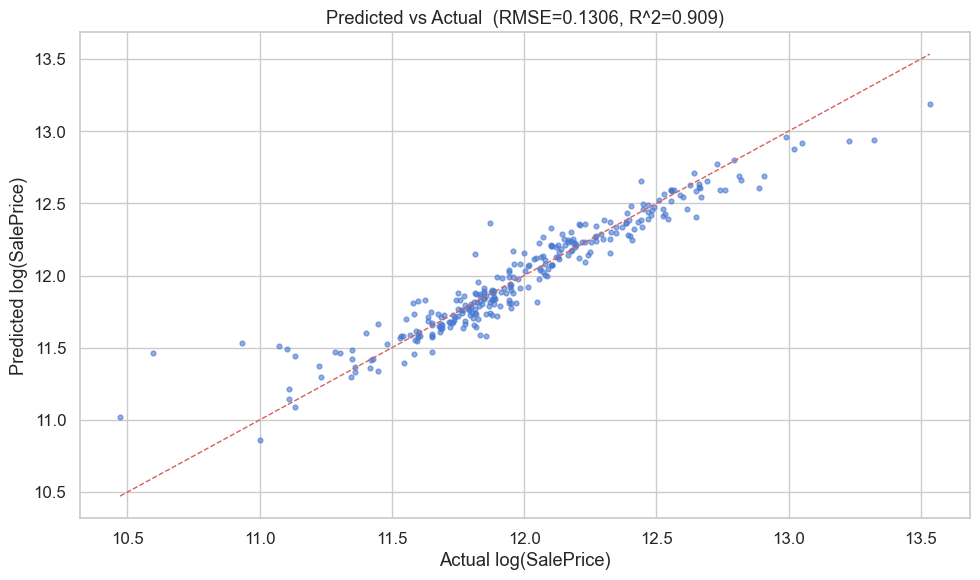

In [2]:
rmse = np.sqrt(mean_squared_error(val["y_true"], val["y_pred"]))
r2 = r2_score(val["y_true"], val["y_pred"])

fig, ax = plt.subplots()
ax.scatter(val["y_true"], val["y_pred"], s=12, alpha=0.6)
lims = [val.min().min(), val.max().max()]
ax.plot(lims, lims, "r--", lw=1)
ax.set_xlabel("Actual log(SalePrice)")
ax.set_ylabel("Predicted log(SalePrice)")
ax.set_title(f"Predicted vs Actual  (RMSE={rmse:.4f}, R^2={r2:.3f})")
plt.tight_layout()
plt.show()

## 3. Residual analysis

Residuals should be centred on zero with no obvious pattern against the prediction.

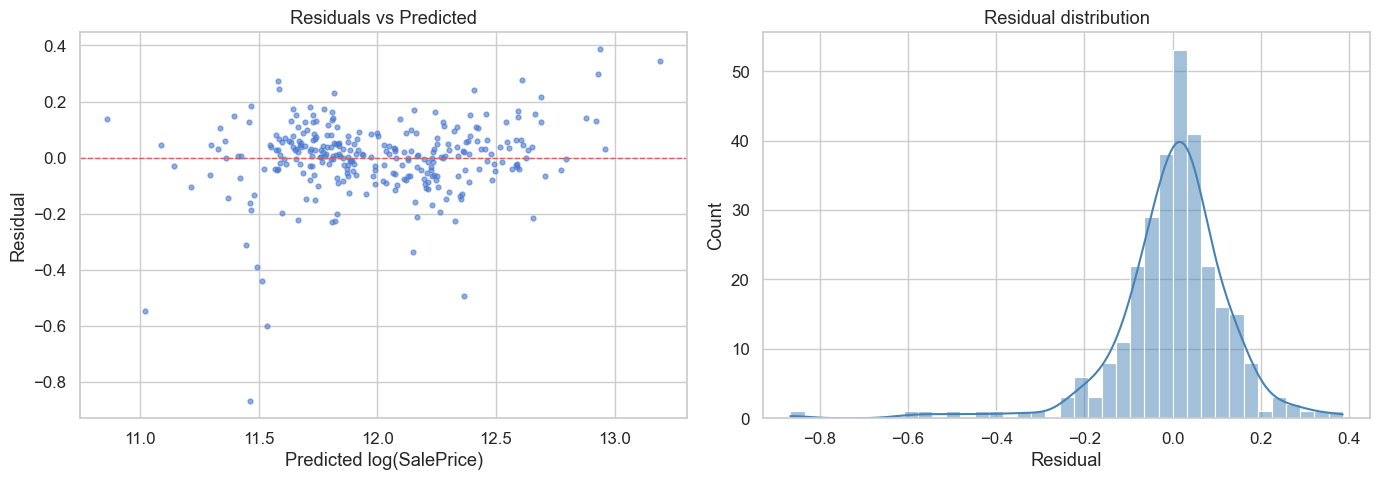

Mean residual: -0.0001  |  Std: 0.1309


In [3]:
val["resid"] = val["y_true"] - val["y_pred"]

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
axs[0].scatter(val["y_pred"], val["resid"], s=12, alpha=0.6)
axs[0].axhline(0, color="r", ls="--", lw=1)
axs[0].set_xlabel("Predicted log(SalePrice)")
axs[0].set_ylabel("Residual")
axs[0].set_title("Residuals vs Predicted")

sns.histplot(val["resid"], kde=True, ax=axs[1], color="steelblue")
axs[1].set_title("Residual distribution")
axs[1].set_xlabel("Residual")
plt.tight_layout()
plt.show()

print(f"Mean residual: {val['resid'].mean():.4f}  |  Std: {val['resid'].std():.4f}")

## 4. What drives the predictions?

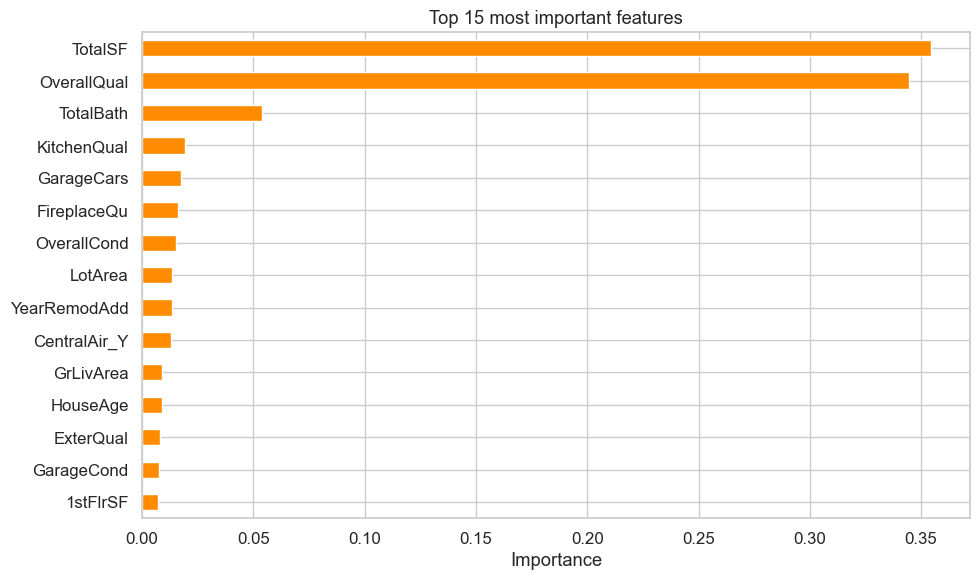

TotalSF         0.354414
OverallQual     0.344751
TotalBath       0.053943
KitchenQual     0.019535
GarageCars      0.017381
FireplaceQu     0.016150
OverallCond     0.015333
LotArea         0.013561
YearRemodAdd    0.013280
CentralAir_Y    0.013198
Name: importance, dtype: float64

In [4]:
importance.head(15).iloc[::-1].plot(kind="barh", color="darkorange")
plt.title("Top 15 most important features")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
importance.head(10)

## 5. Generate the Kaggle submission

Predictions are made on the log target, so they are inverted with `expm1` to get prices in
dollars, then the submission is written in the required `Id,SalePrice` format.

In [5]:
X_test = pd.read_csv(PROC / "test_processed.csv")
test_ids = pd.read_csv(PROC / "test_ids.csv")["Id"]

test_pred = np.expm1(model.predict(X_test))     # back to dollars
submission = pd.DataFrame({"Id": test_ids, "SalePrice": test_pred})

out = Path("../report/submission.csv")
submission.to_csv(out, index=False)
print("wrote", out)
submission.head()

wrote ../report/submission.csv


,Id,SalePrice
0,1461,111333.165537
1,1462,155354.638319
2,1463,179909.015506
3,1464,199566.217678
4,1465,201575.583237


## 6. Conclusions

- The processed feature set (domain-aware imputation, ordinal encoding, engineered
  size/age/bath features, skew correction, one-hot encoding) gives a clean numeric
  matrix that all models train on directly.
- Regularised linear models and Gradient Boosting clearly beat the plain Linear
  Regression baseline, confirming the value of regularisation on this wide one-hot
  feature space.
- The most influential features echo the EDA: overall quality, total/above-grade
  living area and basement size dominate, with neighbourhood and age adding signal.
- Residuals are roughly symmetric and centred on zero — no gross mis-specification —
  with the largest errors on a few unusual, high-end properties.

**Possible next steps:** target/regularisation tuning via grid search, model stacking
(Ridge + GBM), and explicit outlier handling for very large `GrLivArea` homes.